# 1. Introdução e ligação com o CRISP-DM

Este caderno conta o caminho da modelagem do **alerta precoce de onboardings abandonados**: do problema ao modelo que gera a lista semanal. Ele usa a base final criada no caderno 1 (`data/final/onboarding_final_dataset.csv`) e o código de `src/` (`features.py`, `model_utils.py`, `score.py`).

| Fase CRISP-DM | Onde está |
|---|---|
| Entendimento do negócio | seções 1 e 2 deste caderno e caderno 1 |
| Entendimento e preparação dos dados | caderno 1 (qualidade, rótulo, base final, dicionário) |
| **Modelagem** | seções 5 a 9 |
| **Avaliação** | seções 3, 4, 7 e 9 a 10 (divisão temporal, calibração, limiares, explicação) |
| **Implantação** | seção 11 (`src/score.py` e a lista semanal) |

# 2. Por que este projeto

**Escopo original.** Dados os termos de uma oferta (salário, benefícios, período de experiência...), estimar o risco de o contrato terminar antes de 1 ano. Com dados reais, filtros honestos e divisão temporal, o resultado foi fraco (números documentados nas fases do projeto; este caderno **não** executa nem importa aquele projeto):

| Resultado do escopo original (6.419 contratos rotulados, teste = mais recentes) | Valor |
|---|---:|
| AUC do melhor modelo (gradient boosting, 51 atributos) | 0,63 (IC 0,59 a 0,66) |
| Brier do melhor modelo / Brier de chutar a média | 0,221 / 0,235 |
| Só os termos da oferta (sem país, moeda, produto, tipo de contrato) | AUC 0,55 |
| Só as alavancas (salário relativo, aviso, experiência, horas, benefícios) | **AUC 0,53 (acaso)** |
| Perdas capturadas nos 20% de maior risco (acaso = 20%) | 28% |

**A exploração.** Em vez de insistir, o banco Dev foi explorado (somente leitura) em busca de perguntas com desfecho rotulado e custo real. Nove ideias foram avaliadas (abandono de onboarding, saída de cliente, duração do onboarding, depósito pendente, erros de folha, solicitações de férias atrasadas, risco de disputa, conversão de cotações e a pergunta original). **Abandono de onboarding** foi escolhido: 24.647 onboardings com desfecho, cerca de 19% perdidos, sinais precoces mensuráveis (login, tarefas) e uma ação possível (Customer Success).

# 3. Dados, pontos de checagem e divisão

In [1]:
from pathlib import Path
import sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # pasta submission/ (os notebooks ficam em submission/notebooks)
INPUT, FINAL, MODELS, REPORTS = ROOT / "data" / "input", ROOT / "data" / "final", ROOT / "models", ROOT / "reports"
sys.path.insert(0, str(ROOT / "src"))       # features.py, model_utils.py, role_features.py (copias do projeto)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("pasta do pacote:", ROOT)

pasta do pacote: /Users/filipesilva/Documents/datascience/onboarding_early_warning/submission


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.inspection import permutation_importance
import joblib
import features as FE      # src/features.py: atributos conhecidos no dia d
import model_utils as MU   # src/model_utils.py: codificação e gradient boosting (3 sementes)

SEEDS = (0, 1, 2)          # as três sementes do gradient boosting (model_utils.fit)
df = pd.read_csv(FINAL / "onboarding_final_dataset.csv", low_memory=False, parse_dates=["created_at"])
print("base final:", df.shape, "| perdidos:", int(df.y_lost.sum()), f"({df.y_lost.mean():.1%})")

base final: (19855, 122) | perdidos: 3662 (18.4%)


**Pontos de checagem.** Dia 0 (criação), 3, 7 e 14. No dia *d* só entram onboardings **ainda abertos** (`days_to_outcome > d`): é a população que a equipe poderia ajudar.

**Divisão.** *Treino*: criados antes de 2025-01-01. *Teste final (holdout)*: criados de 2025 em diante, pontuado **uma vez**. Os modelos dos dias 3, 7 e 14 treinam a partir de 2023-01-01 (quando o login passa a ser registrado de forma consistente); o dia 0 usa todos os anos. A validação cruzada, quando usada, é **agrupada por cliente**.

**Por que não uma divisão aleatória.** Ela mistura épocas: o modelo aprende padrões do período que depois será testado (taxa de perda e formulários mudam com o tempo). A ferramenta vai pontuar onboardings que ainda não existem, e a divisão temporal é o teste que se parece com isso. (Na validação cruzada dentro dos anos de treino o AUC chegou a 0,79 a 0,90, bem acima do teste temporal 0,69 a 0,78: a divisão aleatória enganaria.)

In [3]:
def populacao(d, dados=None):
    dados = df if dados is None else dados
    m = (dados.days_to_outcome > d) if d else pd.Series(True, index=dados.index)
    if d: m &= dados.created_at >= "2023-01-01"
    x = dados[m]
    return x[x.split_final == "train"].reset_index(drop=True), x[x.split_final == "holdout"].reset_index(drop=True)

ESPERADO = {0: (15083, 4772), 3: (5992, 4519), 7: (5745, 4299), 14: (5298, 3847)}
linhas = []
for d, (n_tr, n_ho) in ESPERADO.items():
    tr, ho = populacao(d)
    assert (len(tr), len(ho)) == (n_tr, n_ho), (d, len(tr), len(ho))
    linhas.append({"checagem": f"dia {d}", "total": len(tr) + len(ho), "treino": len(tr), "teste final": len(ho), "% perdidos treino": 100 * tr.y_lost.mean(), "% perdidos teste": 100 * ho.y_lost.mean()})
display(pd.DataFrame(linhas).round(1))
print("OK: populações conferem (dia 3: 10.511; dia 7: 10.044; dia 14: 9.145).")

,checagem,total,treino,teste final,% perdidos treino,% perdidos teste
0,dia 0,19855,15083,4772,17.800,20.400
1,dia 3,10511,5992,4519,20.400,20.300
2,dia 7,10044,5745,4299,20.500,20.400
3,dia 14,9145,5298,3847,20.900,20.100


OK: populações conferem (dia 3: 10.511; dia 7: 10.044; dia 14: 9.145).


# 4. Métricas e por quê

* **AUC** e **PR-AUC**: quão bem o modelo ordena os onboardings (a taxa de perda é cerca de 20%, então a PR-AUC base é ~0,20).
* **Brier** e **calibração** (erro de calibração em 10 grupos, tabela e curva): a lista mostra "Risco: X%"; X precisa significar X em 100. É a métrica principal para a ferramenta.
* **Perdas capturadas nos 20% de maior risco** (acaso = 20%).
* **Precisão da lista semanal** (top 10 por semana; acaso ≈ 20%): é como a equipe vai usar o resultado.

In [4]:
def ece(y, p, k=10):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)}); t["b"] = pd.qcut(t.p.rank(method="first"), k, labels=False)
    g = t.groupby("b").agg(n=("y", "size"), p=("p", "mean"), o=("y", "mean")); return float((g.n * (g.p - g.o).abs()).sum() / g.n.sum())

def captura20(y, p, frac=0.2, sementes=10):
    y = np.asarray(y); k = int(round(frac * len(y)))
    return float(np.mean([y[np.lexsort((np.random.default_rng(s).random(len(y)), -np.asarray(p)))[:k]].sum() / y.sum() for s in range(sementes)]))

def semanal_topk(ho, p, k):
    w = ho.assign(p=np.asarray(p), sem=pd.to_datetime(ho.created_at).dt.to_period("W"))
    r = [g.sort_values("p", ascending=False).head(k).y_lost.mean() for _, g in w.groupby("sem") if len(g) >= 2 * k]
    return float(np.mean(r))

def avaliar(ho, p):
    p = np.clip(np.asarray(p, float), 1e-4, 1 - 1e-4); y = ho.y_lost.values; const = np.ptp(p) == 0
    return {"AUC": 0.5 if const else roc_auc_score(y, p), "PR-AUC": y.mean() if const else average_precision_score(y, p), "Brier": brier_score_loss(y, p),
            "erro de calibração": ece(y, p) if not const else np.nan, "captura 20%": captura20(y, p), "precisão top-10/sem.": semanal_topk(ho, p, 10)}

def calib_tab(y, p, bins=5):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)}); t["grupo"] = pd.qcut(t.p.rank(method="first"), bins, labels=False)
    return t.groupby("grupo").agg(n=("y", "size"), previsto=("p", "mean"), observado=("y", "mean")).round(3)
print("métricas definidas")

métricas definidas


# 5. Baselines

Três referências **sem aprendizado de máquina**: a taxa de perda do treino (constante), a taxa de perda do país (suavizada) e o histórico do cliente (taxa de perda anterior suavizada).

In [5]:
def base_constante(tr, ho): return np.full(len(ho), tr.y_lost.mean())
def base_pais(tr, ho, M=20):
    g = tr.y_lost.mean(); st = tr.groupby("country").y_lost.agg(["sum", "count"]); taxa = (st["sum"] + M * g) / (st["count"] + M)
    return ho.country.map(taxa).fillna(g).values
def base_cliente(tr, ho): return ho.client_prior_lost_rate.values

linhas = []
for d in (0, 3, 7, 14):
    tr, ho = populacao(d)
    for nome, f in (("constante (taxa do treino)", base_constante), ("taxa do país", base_pais), ("histórico do cliente", base_cliente)):
        linhas.append({"checagem": f"dia {d}", "modelo": nome, **avaliar(ho, f(tr, ho))})
tab_base = pd.DataFrame(linhas); display(tab_base.round(3))

,checagem,modelo,AUC,PR-AUC,Brier,erro de calibração,captura 20%,precisão top-10/sem.
0,dia 0,constante (taxa do treino),0.500,0.204,0.163,NaN,0.200,0.200
1,dia 0,taxa do país,0.576,0.247,0.162,0.038,0.244,0.246
2,dia 0,histórico do cliente,0.585,0.266,0.161,0.037,0.262,0.272
3,dia 3,constante (taxa do treino),0.500,0.203,0.162,NaN,0.196,0.214
4,dia 3,taxa do país,0.580,0.248,0.162,0.028,0.285,0.273
5,dia 3,histórico do cliente,0.583,0.264,0.161,0.035,0.261,0.270
6,dia 7,constante (taxa do treino),0.500,0.204,0.162,NaN,0.205,0.196
7,dia 7,taxa do país,0.570,0.242,0.163,0.037,0.271,0.266
8,dia 7,histórico do cliente,0.577,0.259,0.162,0.039,0.255,0.258
9,dia 14,constante (taxa do treino),0.500,0.201,0.161,NaN,0.194,0.224


# 6. Modelos

Três famílias, todas com os atributos do plano A (seção 7 explica por quê):

* **Regressão logística** (L2): linear, precisa de preenchimento; aqui os vazios numéricos recebem a mediana do **treino**, sem colunas indicadoras.
* **Árvore rasa** (profundidade 3): legível, mostra as regras principais.
* **Gradient boosting** (`HistGradientBoostingClassifier`, profundidade 3, 150 iterações): trata vazios nativamente (vazio continua vazio) e captura interações. É o modelo final (média de 3 sementes: 0, 1 e 2).

In [6]:
def lin_encode(tr, te, cols):
    num = [c for c in cols if c not in MU.CAT]; ca = [c for c in cols if c in MU.CAT]
    med = tr[num].median(); a = tr[num].fillna(med); b = te[num].fillna(med); mu, sd = a.mean(), a.std().replace(0, 1)
    A, B = [((a - mu) / sd).values], [((b - mu) / sd).values]
    for c in ca:
        L = list(tr[c].value_counts()[lambda v: v >= 30].index)
        for l in L: A.append((tr[c] == l).astype(float).values[:, None]); B.append((te[c] == l).astype(float).values[:, None])
        A.append((tr[c].notna() & ~tr[c].isin(L)).astype(float).values[:, None]); B.append((te[c].notna() & ~te[c].isin(L)).astype(float).values[:, None])
    return np.hstack(A), np.hstack(B)

def prever(modelo, tr, ho, cols):
    if modelo == "regressão logística":
        A, B = lin_encode(tr, ho, cols); return LogisticRegression(C=0.05, max_iter=3000).fit(A, tr.y_lost).predict_proba(B)[:, 1]
    if modelo == "árvore rasa (prof. 3)":
        A, B = lin_encode(tr, ho, cols); return DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=0).fit(A, tr.y_lost).predict_proba(B)[:, 1]
    return MU.predict_raw(MU.fit(tr, cols, tr.y_lost, seeds=SEEDS), ho)         # gradient boosting, 3 sementes

PRED = {}
linhas = []
for d in (0, 3, 7, 14):
    tr, ho = populacao(d); cols = FE.feature_list(d)
    for nome in ("regressão logística", "árvore rasa (prof. 3)", "gradient boosting"):
        p = prever(nome, tr, ho, cols); PRED[(d, nome)] = p
        linhas.append({"checagem": f"dia {d}", "modelo": nome, "atributos": len(cols), **avaliar(ho, p)})
tab_modelos = pd.DataFrame(linhas); display(tab_modelos.round(3))

,checagem,modelo,atributos,AUC,PR-AUC,Brier,erro de calibração,captura 20%,precisão top-10/sem.
0,dia 0,regressão logística,19,0.625,0.339,0.155,0.024,0.337,0.347
1,dia 0,árvore rasa (prof. 3),19,0.511,0.211,0.164,0.031,0.216,0.215
2,dia 0,gradient boosting,19,0.613,0.302,0.158,0.028,0.305,0.308
3,dia 3,regressão logística,50,0.743,0.417,0.143,0.031,0.401,0.435
4,dia 3,árvore rasa (prof. 3),50,0.594,0.243,0.158,0.028,0.245,0.266
5,dia 3,gradient boosting,50,0.741,0.413,0.144,0.039,0.410,0.416
6,dia 7,regressão logística,50,0.760,0.445,0.140,0.032,0.418,0.453
7,dia 7,árvore rasa (prof. 3),50,0.610,0.251,0.158,0.030,0.260,0.277
8,dia 7,gradient boosting,50,0.750,0.433,0.143,0.041,0.410,0.445
9,dia 14,regressão logística,50,0.788,0.463,0.135,0.034,0.449,0.455


{0: np.float64(0.613), 3: np.float64(0.741), 7: np.float64(0.75), 14: np.float64(0.777)}
OK: AUC do gradient boosting no teste final = 0,741 / 0,750 / 0,777 (dias 3 / 7 / 14); dia 0 = 0,612


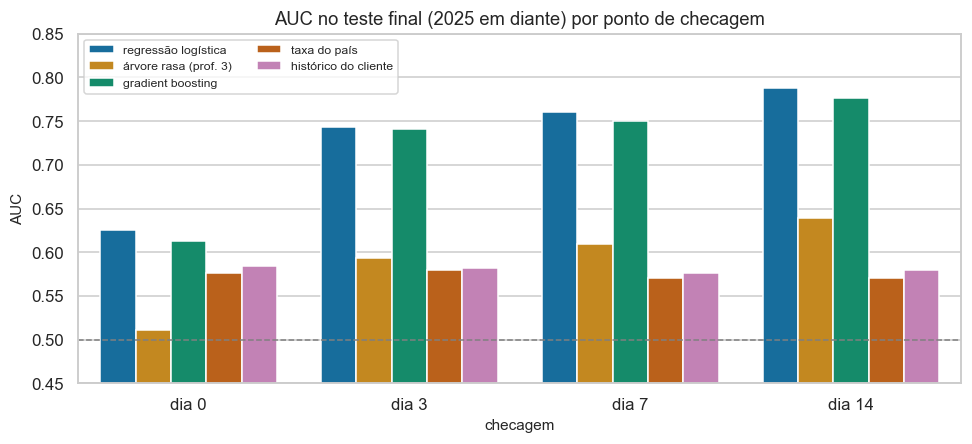

In [7]:
auc_gb = {d: roc_auc_score(populacao(d)[1].y_lost, PRED[(d, "gradient boosting")]) for d in (0, 3, 7, 14)}
print({d: round(v, 3) for d, v in auc_gb.items()})
assert abs(auc_gb[3] - 0.741) < 0.002 and abs(auc_gb[7] - 0.750) < 0.002 and abs(auc_gb[14] - 0.777) < 0.002, auc_gb
assert abs(auc_gb[0] - 0.612) < 0.004, auc_gb[0]
print("OK: AUC do gradient boosting no teste final = 0,741 / 0,750 / 0,777 (dias 3 / 7 / 14); dia 0 = 0,612")

fig, ax = plt.subplots(figsize=(9, 4.2))
t = tab_modelos.copy(); t["checagem"] = t.checagem
sns.barplot(data=pd.concat([t[["checagem", "modelo", "AUC"]], tab_base[tab_base.modelo != "constante (taxa do treino)"][["checagem", "modelo", "AUC"]]]), x="checagem", y="AUC", hue="modelo", ax=ax)
ax.axhline(0.5, color="gray", ls="--", lw=1); ax.set_title("AUC no teste final (2025 em diante) por ponto de checagem"); ax.set_ylim(0.45, 0.85); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Observação importante (resultado não previsto nas fases anteriores).** Com os atributos do plano A (sem termos de oferta), a **regressão logística empata ou supera levemente o gradient boosting** no AUC do teste final: dia 3: 0,743 contra 0,741; dia 7: 0,760 contra 0,750; dia 14: 0,788 contra 0,777; também com erro de calibração bruto menor (0,031 a 0,034 contra 0,039 a 0,041). Nas fases anteriores, com os termos da oferta, o gradient boosting era melhor, e o modelo final foi mantido como gradient boosting (decisão do projeto, não alterada aqui). A diferença é pequena (0,001 a 0,011 de AUC, dentro do intervalo de incerteza de uma única divisão temporal), mas vale uma reavaliação futura: um modelo linear seria mais simples de explicar e de implantar. A árvore rasa fica bem abaixo dos dois.

# 7. O ponto de virada: o experimento de vazamento

Nas primeiras versões o modelo parecia excelente porque lia campos que **só existem depois** do momento do alerta. Dois grupos de atributos foram investigados.

**(a) Campos de emprego preenchidos durante o onboarding** (`pay_frequency`, `contract_type`, `employment_type`). O valor `no_payroll_frequency` vai com 87% de perdas; tipo de emprego vazio vai com 34% de perdas contra 4% quando preenchido. A célula abaixo **refaz o experimento**: acrescenta esses campos (vindos de `data/input/onboardings_day0.csv`) aos atributos do plano A e mede o AUC no teste final.

checagem,dia 0,dia 14,dia 3,dia 7
variante,,,,
plano A (sem esses campos),0.613,0.777,0.741,0.750
+ frequência de pagamento,0.791,0.853,0.826,0.836
+ frequência + tipo de contrato,0.804,0.862,0.843,0.843
+ frequência + contrato + tipo de emprego,0.824,0.857,0.850,0.847


OK: o experimento reproduz os números documentados (dia 0: 0,612 -> 0,792 -> 0,803 -> 0,823).


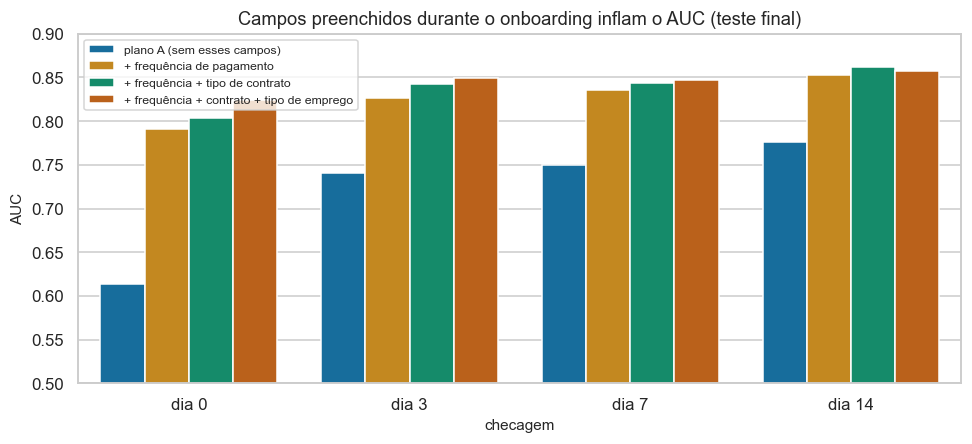

In [8]:
extra = pd.read_csv(INPUT / "onboardings_day0.csv", low_memory=False, usecols=["onboarding_id", "employment_type", "pay_frequency", "contract_type"])
dfx = df.merge(extra, on="onboarding_id", how="left")
CAT_ORIGINAL = list(MU.CAT)
VARIANTES = {"plano A (sem esses campos)": [], "+ frequência de pagamento": ["pay_frequency"], "+ frequência + tipo de contrato": ["pay_frequency", "contract_type"],
             "+ frequência + contrato + tipo de emprego": ["pay_frequency", "contract_type", "employment_type"]}
try:
    MU.CAT = CAT_ORIGINAL + ["pay_frequency", "contract_type", "employment_type"]    # o codificador trata os novos campos como categorias
    linhas = []
    for d in (0, 3, 7, 14):
        tr, ho = populacao(d, dfx)
        for nome, extras in VARIANTES.items():
            p = MU.predict_raw(MU.fit(tr, FE.feature_list(d) + extras, tr.y_lost, seeds=SEEDS), ho)
            linhas.append({"checagem": f"dia {d}", "variante": nome, "AUC": roc_auc_score(ho.y_lost, p), "captura 20%": captura20(ho.y_lost, p), "precisão top-10/sem.": semanal_topk(ho, p, 10)})
finally:
    MU.CAT = CAT_ORIGINAL
vaz = pd.DataFrame(linhas); display(vaz.pivot(index="variante", columns="checagem", values="AUC").loc[list(VARIANTES)].round(3))

DOC = {"dia 0": [0.612, 0.792, 0.803, 0.823], "dia 7": [0.750, 0.836, 0.847, 0.847], "dia 14": [0.777, 0.853, 0.864, 0.858]}
for ck, vals in DOC.items():
    got = vaz[vaz.checagem == ck].AUC.round(3).tolist(); assert all(abs(a - b) < 0.006 for a, b in zip(got, vals)), (ck, got, vals)
print("OK: o experimento reproduz os números documentados (dia 0: 0,612 -> 0,792 -> 0,803 -> 0,823).")

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=vaz, x="checagem", y="AUC", hue="variante", ax=ax)
ax.set_ylim(0.5, 0.9); ax.set_title("Campos preenchidos durante o onboarding inflam o AUC (teste final)"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Com **uma única coluna** (frequência de pagamento) o AUC no dia 0 sobe de 0,61 para 0,79. Nenhum campo honesto de criação faz isso: é o desfecho aparecendo como atributo. Esses campos ficam **fora**.

**(b) Termos da oferta.** A auditoria do Snowflake (relatório documentado em `phases/06_offer_term_timing.md`, números do caderno 1) mostrou que a maioria dos termos é escrita **depois** da criação da oferta (período de experiência: 48% dentro de 1 dia e 47% depois de 14 dias; aviso prévio: 50% e 45%; salário: 46% e 52%). Usá-los no dia *d* lê o futuro em cerca da metade dos casos. Os números abaixo vêm das fases documentadas do projeto (não são recalculados aqui, porque as colunas de oferta não fazem parte do pacote):

| AUC no teste final | Dia 0 | Dia 3 | Dia 7 | Dia 14 |
|---|---:|---:|---:|---:|
| Com os termos da oferta (documentado) | 0,695 | 0,782 | 0,788 | 0,809 |
| **Sem os termos da oferta (plano A)** | **0,612** | **0,741** | **0,750** | **0,777** |
| Precisão top-10/semana com / sem (documentado) | 47% / 31% | 50% / 42% | 50% / 45% | 50% / 45% |

**Decisão (plano A):** nenhum termo de oferta e nenhum dos quatro campos de emprego (`employment_type`, `pay_frequency`, `contract_type`, `contract_salary_present`) entram nos modelos. O dia 0 sem esses campos é fraco (AUC 0,61), então a lista começa no **dia 3**.

# 8. Eventos precoces mais ricos

Os eventos do onboarding são o sinal honesto. Duas versões:

* **v1:** login, informação pessoal, número de tarefas existentes, concluídas e com falha, proporção concluída.
* **v2 (acrescenta):** tarefas concluídas **por tipo** (em especial a **assinatura do contrato pelo funcionário**), dia da primeira e da última tarefa concluída, dias sem atividade e ritmo dos últimos 3 dias.

checagem,dia 14,dia 3,dia 7
atributos,,,
dia 0 + eventos v1,0.715,0.673,0.681
dia 0 + eventos v1 + v2 (plano A final),0.777,0.741,0.750
dia 0 apenas,0.605,0.597,0.606


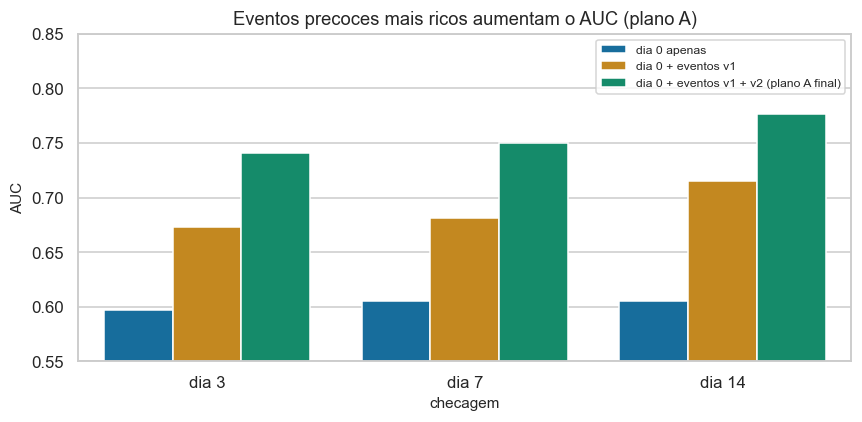

In [9]:
def cols_v1(d): return [c for c in FE.event_cols(d) if c.startswith(("login", "info_", "tasks_"))]
linhas = []
for d in (3, 7, 14):
    tr, ho = populacao(d)
    for nome, cols in (("dia 0 apenas", FE.DAY0), ("dia 0 + eventos v1", FE.DAY0 + cols_v1(d)), ("dia 0 + eventos v1 + v2 (plano A final)", FE.feature_list(d))):
        p = MU.predict_raw(MU.fit(tr, cols, tr.y_lost, seeds=SEEDS), ho)
        linhas.append({"checagem": f"dia {d}", "atributos": nome, "AUC": roc_auc_score(ho.y_lost, p), "captura 20%": captura20(ho.y_lost, p), "precisão top-10/sem.": semanal_topk(ho, p, 10)})
ev = pd.DataFrame(linhas); display(ev.pivot(index="atributos", columns="checagem", values="AUC").round(3))
fig, ax = plt.subplots(figsize=(8, 4)); sns.barplot(data=ev, x="checagem", y="AUC", hue="atributos", ax=ax)
ax.set_ylim(0.55, 0.85); ax.set_title("Eventos precoces mais ricos aumentam o AUC (plano A)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Números documentados **com** termos de oferta, para comparação (fase 5 do projeto): AUC dia 3 / 7 / 14 = 0,727 / 0,719 / 0,751 com os eventos v1 e **0,782 / 0,788 / 0,809** com v1 + v2. No plano A final (sem termos de oferta) o resultado é **0,741 / 0,750 / 0,777**, que a célula acima reproduz. Os eventos mais ricos valem de +0,05 a +0,07 de AUC sobre os eventos v1.

# 9. Modelos finais, calibração e limiares

Para cada checkpoint (dias 3, 7 e 14):

1. **Avaliação honesta:** modelo treinado antes de 2025, pontuado no teste final (2025 em diante).
2. **Calibração:** regressão isotônica ajustada nas previsões **fora do tempo**; para medir o erro sem enviesar, a calibração é *validada cruzada por semana* (semanas pares calibram as ímpares e vice-versa).
3. **Modelo de produção:** mesmas configurações, treinado em **todos** os rotulados da população; a calibração usada em produção é a isotônica ajustada nas previsões do teste final.
4. Os modelos são salvos em `models/checkpoint_d{3,7,14}.joblib`, no formato que `src/score.py` lê.

In [10]:
MODELS.mkdir(exist_ok=True)
prior = float(df[df.created_at < "2025-01-01"].y_lost.mean())
EVAL, AVAL = {}, {}
for d in (3, 7, 14):
    cols = FE.feature_list(d); tr, ho = populacao(d); pop = pd.concat([tr, ho], ignore_index=True)
    b_eval = MU.fit(tr, cols, tr.y_lost, seeds=SEEDS); p = MU.predict_raw(b_eval, ho)
    sem = pd.to_datetime(ho.created_at).dt.to_period("W").astype(str); ordem = {w: i for i, w in enumerate(sorted(sem.unique()))}; metade = (sem.map(ordem) % 2).values
    pc = np.zeros(len(ho))
    for h in (0, 1):
        pc[metade == h] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p[metade != h], ho.y_lost.values[metade != h]).predict(p[metade == h])
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, ho.y_lost.values)
    b_prod = MU.fit(pop, cols, pop.y_lost, seeds=SEEDS); comp = pop[pop.y_lost == 0]
    ref = {c: float(comp[c].quantile(0.75)) for c in cols if c not in MU.CAT and comp[c].notna().any()}
    ref_low = {c: float(comp[c].quantile(0.25)) for c in cols if c not in MU.CAT and comp[c].notna().any()}
    semanas = len(ordem); linha = {"dia": d, "treino": len(tr), "teste final": len(ho), "AUC": roc_auc_score(ho.y_lost, p), "Brier bruto": brier_score_loss(ho.y_lost, p), "Brier calibrado": brier_score_loss(ho.y_lost, pc),
                                  "erro calibração bruto": ece(ho.y_lost, p), "erro calibração calibrado": ece(ho.y_lost, pc)}
    for t in (0.30, 0.35, 0.40):
        fl = pc >= t; linha[f"sinalizados/sem. >= {round(t * 100)}%"] = fl.sum() / semanas; linha[f"precisão >= {round(t * 100)}%"] = ho.y_lost.values[fl].mean(); linha[f"captura >= {round(t * 100)}%"] = ho.y_lost.values[fl].sum() / ho.y_lost.sum()
    EVAL[d] = linha; AVAL[d] = dict(tr=tr, ho=ho, b_eval=b_eval, p=p, pc=pc, cols=cols)
    joblib.dump(dict(bundle=b_prod, iso=iso, ref=ref, ref_low=ref_low, prior_lost_rate=prior, day=d, trained_rows=len(pop), trained_until=str(pop.created_at.max().date()), eval=linha), MODELS / f"checkpoint_d{d}.joblib")
res = pd.DataFrame(EVAL).T; display(res[["treino", "teste final", "AUC", "Brier bruto", "Brier calibrado", "erro calibração bruto", "erro calibração calibrado"]].round(3))
print("modelos salvos:", sorted(p.name for p in MODELS.glob("*.joblib")))

,treino,teste final,AUC,Brier bruto,Brier calibrado,erro calibração bruto,erro calibração calibrado
3,"5,992.000","4,519.000",0.741,0.144,0.143,0.039,0.013
7,"5,745.000","4,299.000",0.750,0.143,0.141,0.041,0.012
14,"5,298.000","3,847.000",0.777,0.137,0.135,0.039,0.020


modelos salvos: ['checkpoint_d14.joblib', 'checkpoint_d3.joblib', 'checkpoint_d7.joblib']


OK: AUC 0,741 / 0,750 / 0,777; erro de calibração bruto 0,039-0,041 -> calibrado [0.013, 0.012, 0.02] (documentado: 0,014 / 0,019 / 0,016; diferença por desempate de valores iguais)


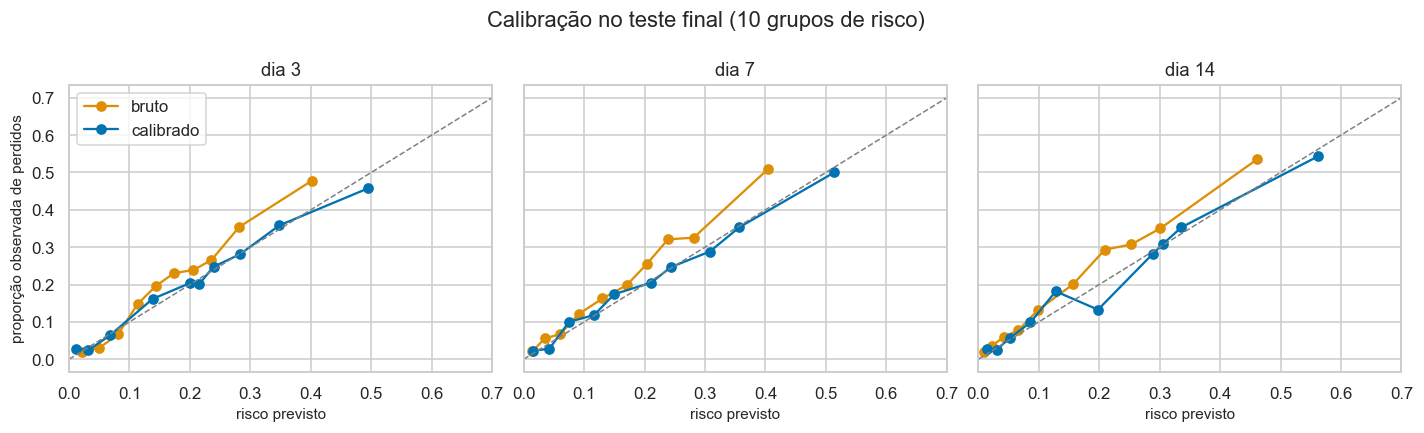

In [11]:
assert [round(EVAL[d]["AUC"], 3) for d in (3, 7, 14)] == [0.741, 0.750, 0.777], [EVAL[d]["AUC"] for d in (3, 7, 14)]
assert all(abs(EVAL[d]["erro calibração bruto"] - a) < 0.003 for d, a in zip((3, 7, 14), (0.039, 0.041, 0.039)))
# o erro calibrado documentado foi 0,014 / 0,019 / 0,016; aqui sai um valor um pouco diferente porque a isotônica gera muitos valores idênticos e o
# agrupamento em 10 grupos de mesmo tamanho desempata pela ordem das linhas (a base final está ordenada por onboarding_id). A conclusão não muda.
assert all(0.010 <= EVAL[d]["erro calibração calibrado"] <= 0.022 for d in (3, 7, 14)), [EVAL[d]["erro calibração calibrado"] for d in (3, 7, 14)]
assert all(EVAL[d]["erro calibração calibrado"] < 0.6 * EVAL[d]["erro calibração bruto"] for d in (3, 7, 14))
print("OK: AUC 0,741 / 0,750 / 0,777; erro de calibração bruto 0,039-0,041 -> calibrado", [round(EVAL[d]["erro calibração calibrado"], 3) for d in (3, 7, 14)], "(documentado: 0,014 / 0,019 / 0,016; diferença por desempate de valores iguais)")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, d in zip(axes, (3, 7, 14)):
    a = AVAL[d]; y = a["ho"].y_lost.values
    for nome, pp, cor in (("bruto", a["p"], sns.color_palette("colorblind")[1]), ("calibrado", a["pc"], sns.color_palette("colorblind")[0])):
        t = pd.DataFrame({"y": y, "p": pp}); t["g"] = pd.qcut(t.p.rank(method="first"), 10, labels=False); g = t.groupby("g").agg(p=("p", "mean"), o=("y", "mean"))
        ax.plot(g.p, g.o, "o-", color=cor, label=nome)
    ax.plot([0, .7], [0, .7], "--", color="gray", lw=1); ax.set_title(f"dia {d}"); ax.set_xlabel("risco previsto"); ax.set_xlim(0, .7)
axes[0].set_ylabel("proporção observada de perdidos"); axes[0].legend(); fig.suptitle("Calibração no teste final (10 grupos de risco)"); plt.tight_layout(); plt.show()

In [12]:
lim = pd.DataFrame(EVAL).T
tabela = pd.DataFrame({f"dia {d}": {f"risco >= {t}%": f"{lim.loc[d, f'sinalizados/sem. >= {t}%']:.1f} por semana, precisão {100 * lim.loc[d, f'precisão >= {t}%']:.0f}%, captura {100 * lim.loc[d, f'captura >= {t}%']:.0f}%" for t in (30, 35, 40)} for d in (3, 7, 14)})
display(tabela)
ok35 = [(8.1, 0.441), (9.9, 0.426), (5.6, 0.520)]
for d, (n, pr) in zip((3, 7, 14), ok35):
    assert abs(lim.loc[d, "sinalizados/sem. >= 35%"] - n) < 0.2 and abs(lim.loc[d, "precisão >= 35%"] - pr) < 0.01, (d, lim.loc[d].to_dict())
print("OK: com risco >= 35% saem 6 a 10 onboardings por semana, com 43% a 52% de precisão (acaso: 20%).")

,dia 3,dia 7,dia 14
risco >= 30%,"13.6 por semana, precisão 40%, captura 45%","15.0 por semana, precisão 40%, captura 52%","13.2 por semana, precisão 41%, captura 53%"
risco >= 35%,"8.1 por semana, precisão 44%, captura 29%","9.9 por semana, precisão 43%, captura 37%","5.6 por semana, precisão 52%, captura 29%"
risco >= 40%,"6.5 por semana, precisão 46%, captura 25%","6.1 por semana, precisão 49%, captura 26%","4.2 por semana, precisão 60%, captura 25%"


OK: com risco >= 35% saem 6 a 10 onboardings por semana, com 43% a 52% de precisão (acaso: 20%).


**Leitura.** Com risco calibrado **>= 35%** a equipe recebe de 6 a 10 onboardings por semana e 43% a 52% deles terminam perdidos, contra 20% por acaso. Com 30% a lista cresce (13 a 15 por semana) e a precisão cai para cerca de 40%. O limiar recomendado é **35%**.

# 10. Explicação do modelo

* **Importância por permutação** no teste final: quanto o AUC cai quando um atributo é embaralhado.
* **"Razões se corrigidas"** (método de `score.py`): para cada onboarding, cada sinal corrigível (login, informação pessoal, assinatura do contrato, documentos, depósito, tarefas feitas, dias sem atividade, histórico do cliente) é trocado por um valor "no caminho certo" (percentil 75 dos concluídos; percentil 25 para os sinais em que menor é melhor) e mede-se quanto o risco cai. Os três maiores cortes viram as razões. São **associações** do modelo, não prova de causa.

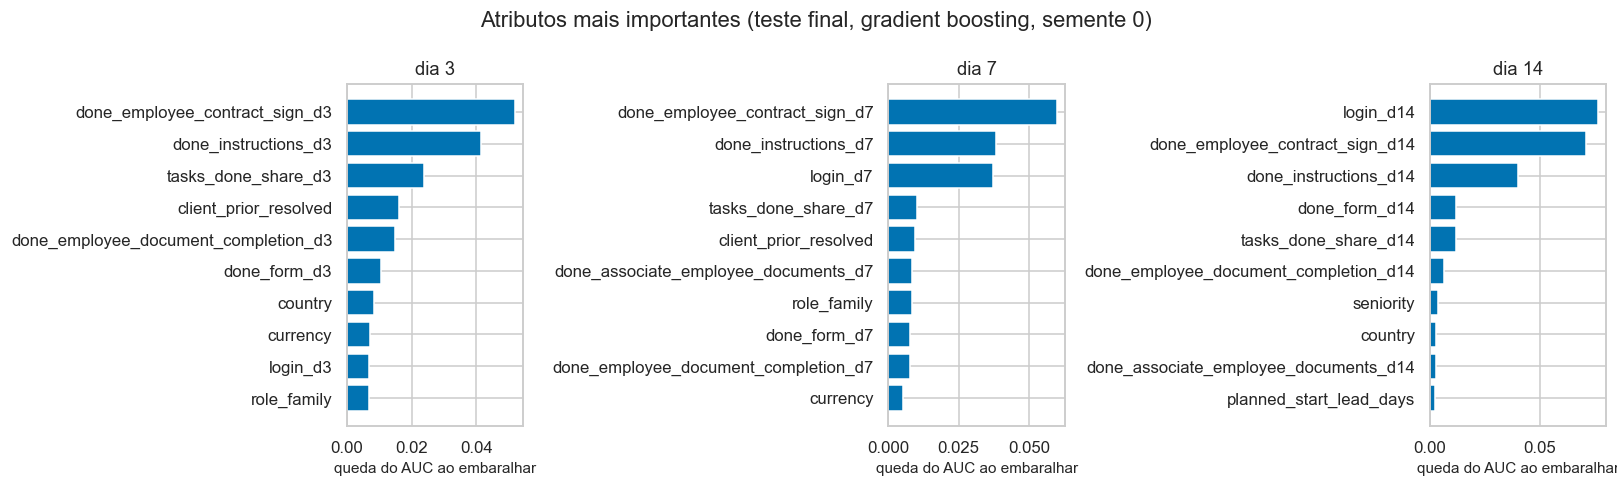

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, d in zip(axes, (3, 7, 14)):
    a = AVAL[d]; cols = a["cols"]; Xh, _ = MU.encode(a["ho"], cols, a["b_eval"]["levels"]); m0 = a["b_eval"]["models"][0]
    pi = permutation_importance(m0, Xh, a["ho"].y_lost, scoring="roc_auc", n_repeats=5, random_state=0)
    nomes = [c for c in cols if c not in MU.CAT] + [c for c in cols if c in MU.CAT]
    imp = pd.Series(pi.importances_mean, index=nomes).sort_values(ascending=False).head(10)[::-1]
    ax.barh(imp.index, imp.values, color=sns.color_palette("colorblind")[0]); ax.set_title(f"dia {d}"); ax.set_xlabel("queda do AUC ao embaralhar")
plt.suptitle("Atributos mais importantes (teste final, gradient boosting, semente 0)"); plt.tight_layout(); plt.show()

In [14]:
d = 7; a = AVAL[d]; ho = a["ho"].copy(); ho["risco_calibrado"] = a["pc"]
top = ho.sort_values("risco_calibrado", ascending=False).head(int(0.2 * len(ho)))
lr = ho[ho.y_lost == 1].lost_reason.fillna("(sem motivo)").value_counts(); tp = top[top.y_lost == 1].lost_reason.fillna("(sem motivo)").value_counts()
motivos = pd.DataFrame({"perdidos no teste": lr, "capturados nos 20% de maior risco": (tp / lr).fillna(0).round(2)}); display(motivos[motivos["perdidos no teste"] >= 15].head(10))

visto = ho.client_uid.isin(set(a["tr"].client_uid)).values
print(f"AUC dia {d}: clientes vistos no treino {roc_auc_score(ho.y_lost[visto], a['p'][visto]):.3f} ({visto.sum()} linhas) | clientes NÃO vistos {roc_auc_score(ho.y_lost[~visto], a['p'][~visto]):.3f} ({(~visto).sum()} linhas)")
paises = ho.country.value_counts().head(6).index
por_pais = pd.DataFrame([{"país": c, "n": int((ho.country == c).sum()), "perdidos observados": ho.y_lost[ho.country == c].mean(), "risco médio previsto": ho.risco_calibrado[ho.country == c].mean(),
                          "AUC": roc_auc_score(ho.y_lost[ho.country == c], a["p"][(ho.country == c).values])} for c in paises]); display(por_pais.round(3))

,perdidos no teste,capturados nos 20% de maior risco
lost_reason,,
accepted_other_opportunity_personal_decision,15,0.000
admin_or_user_error,225,0.600
client_decided_not_to_enter_market,20,0.350
client_decided_not_to_move_forward_with_candidate,168,0.370
client_delayed_onboarding_more_than_two_months,23,0.350
client_hired_directly_opened_own_entity,29,0.240
employee_received_counter_offer,28,0.250
employee_rejected_offer,157,0.340
employee_resigned,23,0.390


AUC dia 7: clientes vistos no treino 0.742 (2689 linhas) | clientes NÃO vistos 0.752 (1610 linhas)


,país,n,perdidos observados,risco médio previsto,AUC
0,CA,369,0.176,0.130,0.787
1,GB,343,0.169,0.149,0.660
2,IN,294,0.160,0.233,0.785
3,BR,169,0.059,0.087,0.814
4,PH,151,0.139,0.162,0.802
5,MX,143,0.168,0.130,0.791


**Leitura da tabela de motivos (plano A, dia 7).** Nos 20% de maior risco ficam **60%** dos perdidos por *erro administrativo ou de usuário* (225 casos), 37% dos *cliente decidiu não seguir com o candidato* e 34% dos *funcionário rejeitou a oferta*. As fases anteriores citavam 76% para o erro administrativo; esse número vinha do modelo **com termos de oferta**, que o plano A descarta. No plano A o modelo continua achando melhor os erros administrativos (a causa mais evitável) do que as decisões do funcionário, mas com menos folga.

In [15]:
ROTULOS = {"login": "o funcionário ainda não fez login", "info_done": "informação pessoal não concluída", "done_employee_contract_sign": "contrato não assinado",
           "done_employee_data_completion": "dados do funcionário não preenchidos", "done_employee_document_completion": "documentos do funcionário não concluídos",
           "done_deposit_invoice": "fatura de depósito pendente", "done_payment_verification": "verificação de pagamento pendente", "done_form": "formulários não concluídos"}

def razoes(B, G, d, top=3):
    # mesmo método de src/score.py, com rótulos em português
    risco = B["iso"].predict(MU.predict_raw(B["bundle"], G)); cand = []
    for k, lab in ROTULOS.items():
        c = f"{k}_d{d}"; cand.append((c, lab, 1.0 if k in ("login", "info_done") else max(1.0, B["ref"].get(c, 1.0)), lambda x: x < 1))
    cand += [(f"tasks_done_share_d{d}", "poucas tarefas concluídas", B["ref"][f"tasks_done_share_d{d}"], lambda x: x < B["ref"][f"tasks_done_share_d{d}"]),
             (f"days_since_last_done_d{d}", "nenhuma tarefa concluída recentemente", B["ref_low"][f"days_since_last_done_d{d}"], lambda x: x > B["ref_low"][f"days_since_last_done_d{d}"]),
             ("client_prior_lost_rate", "cliente com taxa de perda anterior alta", B["ref_low"]["client_prior_lost_rate"], lambda x: x > B["ref_low"]["client_prior_lost_rate"])]
    quedas = np.zeros((len(G), len(cand)))
    for j, (c, lab, ref, ruim) in enumerate(cand):
        H = G.copy(); aplica = G[c].map(lambda x: (pd.isna(x) and c.startswith("days_since")) or (not pd.isna(x) and ruim(x))).values; H[c] = ref
        quedas[:, j] = np.where(aplica, risco - B["iso"].predict(MU.predict_raw(B["bundle"], H)), 0.0)
    out = []
    for i in range(len(G)):
        t = [(cand[j][1], quedas[i, j]) for j in np.argsort(-quedas[i])[:top] if quedas[i, j] >= 0.01]
        out.append({"risco": f"{100 * risco[i]:.0f}%", "razões (queda do risco se corrigido)": "; ".join(f"{lab} (-{100 * q:.0f} pts)" for lab, q in t) or "nenhum sinal corrigível isolado"})
    return pd.DataFrame(out)

B7 = joblib.load(MODELS / "checkpoint_d7.joblib")
amostra = ho.sort_values("risco_calibrado", ascending=False).head(5).reset_index(drop=True)
demo = razoes(B7, amostra, 7); demo.insert(0, "onboarding (emp_)", amostra.employment_uid.str[:12] + "...")
print("Demonstração do método com o modelo de produção do dia 7 em 5 onboardings de maior risco do teste final. Atenção: essas linhas fazem parte do treino do modelo de produção, por isso os riscos aparecem mais extremos do que seriam em onboardings novos (um exemplo real está na seção 11). As razões descrevem o modelo; não são prova de causa.")
display(demo)

Demonstração do método com o modelo de produção do dia 7 em 5 onboardings de maior risco do teste final. Atenção: essas linhas fazem parte do treino do modelo de produção, por isso os riscos aparecem mais extremos do que seriam em onboardings novos (um exemplo real está na seção 11). As razões descrevem o modelo; não são prova de causa.


,onboarding (emp_),risco,razões (queda do risco se corrigido)
0,emp_3mXVpzrw...,97%,contrato não assinado (-55 pts); documentos do...
1,emp_009TxmyH...,100%,contrato não assinado (-74 pts); o funcionário...
2,emp_6CkoFGlx...,83%,contrato não assinado (-49 pts); o funcionário...
3,emp_5juOAkgE...,90%,contrato não assinado (-56 pts); o funcionário...
4,emp_1h0mYEgu...,92%,contrato não assinado (-46 pts); documentos do...


# 11. Implantação: a lista semanal

`src/score.py` (cópia do script do projeto, com os caminhos ajustados para `submission/`) produz a lista:

1. consulta o banco **Dev em modo somente leitura** (`dbv`, com o SQL de `sql/`) e reconstrói os mesmos atributos com `src/features.py`;
2. seleciona os onboardings em andamento que **chegaram ao dia 3, 7 ou 14 nos últimos 7 dias** (`--window`), ou todos (`--all-open`);
3. pontua cada um com o modelo do checkpoint (`models/checkpoint_d{3,7,14}.joblib`), com a calibração isotônica;
4. marca como **sinalizados** os de risco >= 35% (`--threshold`) e escreve `reports/weekly_list_<data>.csv` e `.md`, com "Risco: X% / Sucesso: Y%" e até três razões.

**Este caderno não executa a consulta ao banco.** Abaixo, o trecho principal do código e um exemplo real da lista (apenas identificadores, nenhum nome).

In [16]:
chaves = ("np.select", "age_days", "predict_raw", "iso\"].predict", "risk_pct", "flag=", "--threshold", "--window", "--include-pending-deposit")
trechos = [l.rstrip()[:170] for l in (ROOT / "src" / "score.py").read_text(encoding="utf-8").splitlines() if any(k in l for k in chaves)]
print("trechos de src/score.py:"); print("\n".join(trechos[:14]))

trechos de src/score.py:
Usage: python score.py [--window 7] [--threshold 0.35] [--all-open] [--out reports]"""
ap = argparse.ArgumentParser(); ap.add_argument("--window", type=int, default=7, help="days after a checkpoint during which the onboarding stays on the list"); ap.add_arg
ap.add_argument("--all-open", action="store_true", help="score every open onboarding at its latest checkpoint, not only those that reached it recently"); ap.add_argument(
M["age_days"] = (now - M.created_at).dt.total_seconds() / 86400
OPEN = ["in_progress"] + (["pending_deposit"] if a.include_pending_deposit else []); O = M[M.status.isin(OPEN) & ~M.is_dedup & (M.age_days >= 3)].copy(); O["checkpoint"] 
if not a.all_open: O = O[(O.age_days - O.checkpoint) < a.window]
print(f"as of {now.date()} | open ({'+'.join(OPEN)}) onboardings with at least 3 days of age: {int((M.status.isin(OPEN) & ~M.is_dedup & (M.age_days >= 3)).sum())} | on th
if len(O) == 0: sys.exit("nothing to score in this window (try --window 30 

In [17]:
lista = pd.read_csv(REPORTS / "weekly_list_2026-11-16.csv")
print("lista de exemplo (2026-11-16):", lista.shape, "| sinalizados (risco >= 35%):", int(lista.flag.sum()))
display(lista.head(8)[["employment_uid", "client_uid", "country", "checkpoint_day", "age_days", "risk_pct", "success_pct", "flag", "reasons"]])
# o artefato salvo funciona: pontua algumas linhas do teste final com o arquivo .joblib
B14 = joblib.load(MODELS / "checkpoint_d14.joblib"); g = AVAL[14]["ho"].head(5)
print("risco calibrado (dia 14, 5 linhas do teste, modelo de produção):", np.round(B14["iso"].predict(MU.predict_raw(B14["bundle"], g)), 3).tolist())

lista de exemplo (2026-11-16): (49, 12) | sinalizados (risco >= 35%): 11


,employment_uid,client_uid,country,checkpoint_day,age_days,risk_pct,success_pct,flag,reasons
0,emp_09RJ4up7kvKgnutTMxlyfX,cmp_0344u4X8GI5fwkxOlLMfgd,NL,7,10,68,32,True,contract not signed (-56 pts if fixed); employ...
1,emp_5K3cmjhNrFYN1BSn7RC7tS,cmp_n1eqsmu1a1ett1Zrqt1csu,CH,7,13,68,32,True,contract not signed (-43 pts if fixed); employ...
2,emp_10I8XLjFOI9ktqF1j0NYUg,cmp_034l3lDIl4z6TjR4IaaJdI,AU,14,16,54,46,True,employee has not logged in (-42 pts if fixed);...
3,emp_4745rE8mRpdXTF3gGJv8Sv,cmp_ompvv1bm1eo1dooqun1cu1,NL,14,16,54,46,True,contract not signed (-38 pts if fixed); employ...
4,emp_4rUvsYqHgbE16N1xNprjWR,cmp_st1em1a1a1co1erntqn1ao,UY,14,19,54,46,True,contract not signed (-42 pts if fixed); employ...
5,emp_2J0VkklceVpiCkSHdlBxBu,cmp_1bp1e1b1c1c1Zq1a1dv1aq,IT,7,10,42,58,True,contract not signed (-32 pts if fixed); employ...
6,emp_79lRqSneEwTHbIZeNpS8FU,cmp_034nuUCHkXN1XAhiTMOUGJ,GB,7,11,42,58,True,contract not signed (-32 pts if fixed); employ...
7,emp_3lAmzvbn58xBciT1qRb9al,cmp_qn1d1e1Zmsq1dmt1aqt1Z1,US,7,12,42,58,True,contract not signed (-35 pts if fixed); employ...


risco calibrado (dia 14, 5 linhas do teste, modelo de produção): [0.218, 0.218, 0.121, 0.03, 0.129]


# 12. Limites e próximos passos

* **Uma única divisão temporal** (treino antes de 2025, teste de 2025 em diante); a precisão semanal é uma média de 70 a 76 semanas. É preciso reavaliar a cada trimestre contra os desfechos reais.
* **`pending_deposit`.** Há 1.226 onboardings nessa etapa (uma novidade de 2026) que **não são pontuados**: os modelos foram treinados com 2023 a 2025, quando a etapa quase não existia.
* **Tempo dos eventos.** Uma tarefa conta como concluída quando seu `updated_at` é anterior ao ponto de checagem; edições posteriores podem fazer a contagem ficar um pouco baixa.
* **O que o modelo não vê:** termos da oferta e campos preenchidos durante o onboarding (plano A) e qualquer coisa depois do dia 14. O dia 0 não é pontuado (AUC 0,61).
* **Associações, não causas.** As razões mostram o que costuma acompanhar onboardings concluídos; corrigir um sinal não garante o desfecho.
* **Próximos passos.** Execução semanal agendada que grava a lista em `reports/`; reavaliação trimestral e novo treino; estudar o `pending_deposit`; se os termos da oferta puderem ser datados com segurança (escritos até o dia *d*), reconsiderá-los.